In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

Etapa 1 (Entendimento): Identificamos que o problema é de classificação. É crucial separar corretamente o que são as features (variáveis explicativas) e o label (o que queremos prever).

Etapa 2 (EDA): Utilizamos histogramas para entender a distribuição e a matriz de correlação para verificar se existe redundância nos dados. Isso ajuda a evitar que variáveis irrelevantes confundam a rede neural.

Colunas do dataset: Index([0, 1, 2], dtype='int64')
Primeiras linhas:
            0          1  2
0 -19.273006 -18.236898  1
1 -20.106840 -20.714055  1
2 -21.396553 -22.397874  1
3 -19.971450 -19.914267  1
4 -23.340873 -21.380371  1


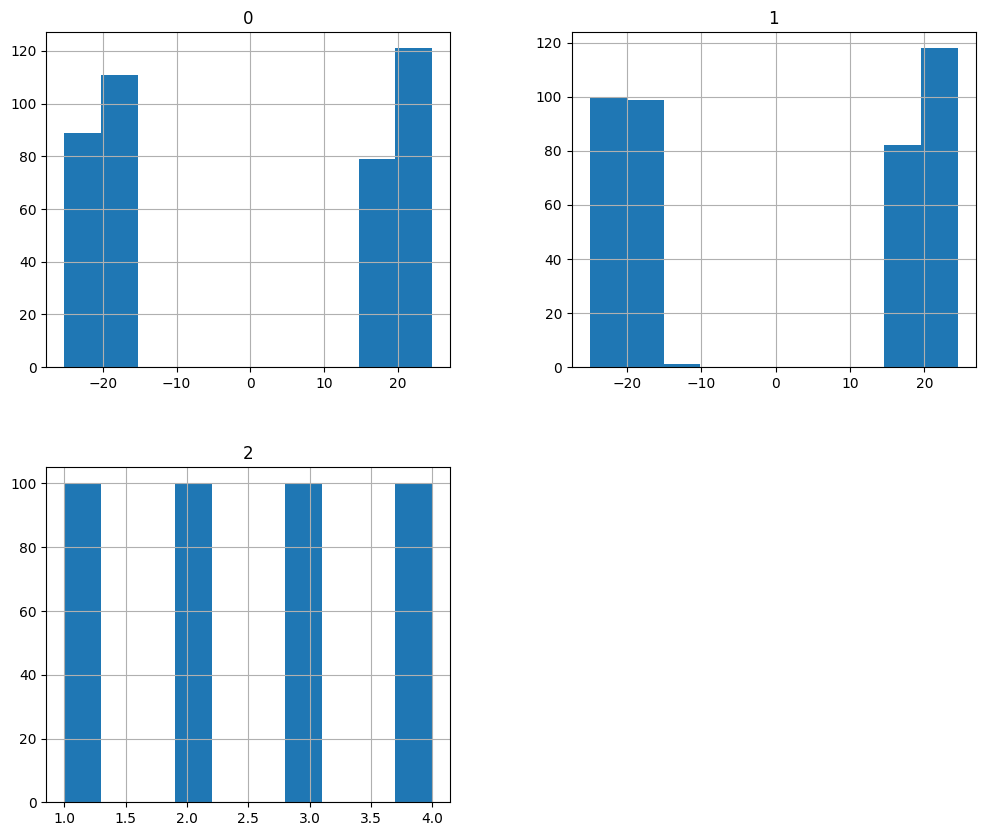

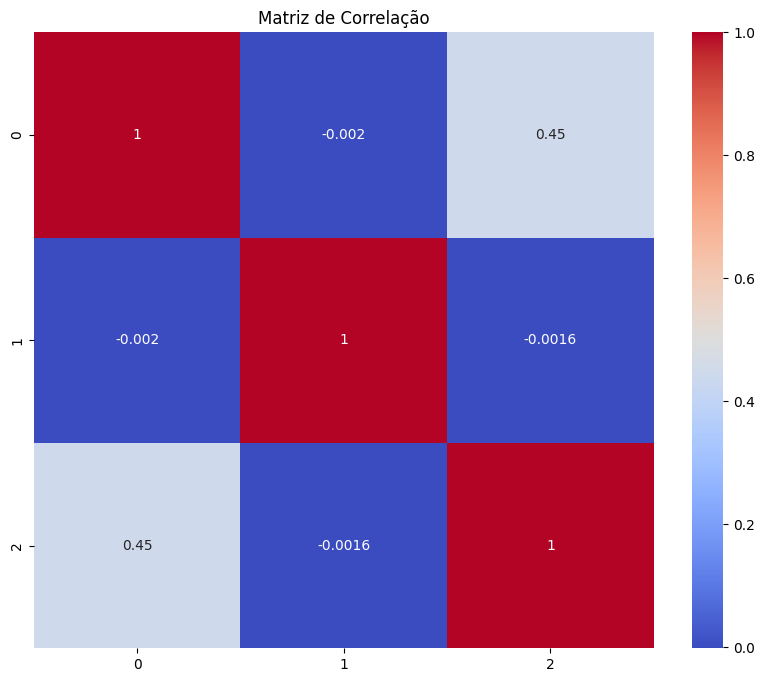

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definição da função (o return encerra a função)
def carregar_csv(caminho):
    df = pd.read_csv(caminho, header=None, names=[0, 1, 2])

    df[0] = df[0].astype(str).str.replace('"', '').str.replace(',', '.').astype(float)
    df[1] = df[1].astype(str).str.replace('"', '').str.replace(',', '.').astype(float)
    df[2] = df[2].astype(int)

    dados = df[[0, 1]].values
    rotulos = df[2].values - 1

    return df, dados, rotulos

df, dados, rotulos = carregar_csv('Base4.csv')

# 3. Etapa 1: Entendimento
print("Colunas do dataset:", df.columns)
print("Primeiras linhas:\n", df.head())

# 4. Etapa 2: Análise Exploratória (EDA)
df.hist(figsize=(12, 10))
plt.show()

# Matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Matriz de Correlação")
plt.show()

Etapa 4 (Escalonamento): Como as ANNs realizam cálculos matemáticos baseados nos pesos dos neurônios, atributos com escalas diferentes podem causar instabilidade no treinamento. O StandardScaler garante que todos os atributos estejam na mesma "escala de importância".

In [9]:
# Etapa 4: Escalonamento dos dados
# Separando features (X) do target (y)
# Supondo que sua coluna alvo se chame 'target'
X = df[[0, 1]]
y = df[2]

# Aplicando a padronização
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Transformando de volta em DataFrame para facilitar a visualização
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Dados escalonados (primeiras 5 linhas):\n", X_scaled_df.head())

Dados escalonados (primeiras 5 linhas):
           0         1
0 -0.951445 -0.912097
1 -0.992529 -1.035694
2 -1.056074 -1.119707
3 -0.985858 -0.995788
4 -1.151873 -1.068939


Etapa 5 (Implementação da Separação): Como precisamos dividir em três partes, fazemos o processo em dois passos: primeiro separamos o treino e o resto, e depois dividimos o "resto" em validação e teste.
- Treino (70%): É usado pelo algoritmo para aprender os pesos das conexões neurais durante o forward propagation e backpropagation.  
- Validação (15%): Essencial para monitorar o treinamento e ajustar hiperparâmetros (como número de épocas, taxa de aprendizado ou número de neurônios) sem enviesar o modelo. Ajuda a detectar o overfitting precocemente.  
- Teste (15%): Atua como o "juiz final". O modelo nunca "vê" esses dados durante o treinamento ou ajuste, fornecendo uma métrica imparcial do quão bem ele generaliza para novos dados.  

In [10]:
from sklearn.model_selection import train_test_split

# 1. Primeiro: Separar em Treino (70%) e Resto (30%)
# X_scaled é o conjunto que você escalonou na Etapa 4
X_train, X_rest, y_train, y_rest = train_test_split(
    X_scaled, y, test_size=0.30, random_state=42
)

# 2. Segundo: Separar o Resto em Validação (15%) e Teste (15%)
# Como o Resto era 30% do total, dividimos ele ao meio (0.5 de 0.3 = 0.15)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=42
)

print(f"Tamanho do treino: {len(X_train)} amostras")
print(f"Tamanho da validação: {len(X_val)} amostras")
print(f"Tamanho do teste: {len(X_test)} amostras")

Tamanho do treino: 280 amostras
Tamanho da validação: 60 amostras
Tamanho do teste: 60 amostras
